# 02 · Analisis Data: Prediksi Harga & Peringatan Dini Lonjakan
## Early Warning System Harga Pangan Strategis Kab/Kota Jawa Barat

**UAS AI for Innovation — Magister Inovasi Regional 2026/2027**

Notebook ini menjawab komponen laporan:
- **(e) Pengujian apakah AI benar-benar diperlukan** — model AI dibandingkan secara adil dengan pendekatan non-AI
- **(h) Analisis data** — pemodelan, evaluasi, interpretasi
- Menghasilkan berkas data untuk **(i) dashboard**

**Dua AI task**
| AI task | Pertanyaan | Output |
|---|---|---|
| Regresi (*forecasting*) | Berapa harga 1–4 minggu ke depan? | harga prediksi + interval 80 % |
| Klasifikasi (*early warning*) | Seberapa besar peluang harga naik > 10 % dalam 4 minggu? | probabilitas → status hijau/kuning/merah |

**Struktur notebook**
1. Setup & data
2. Rekayasa fitur & target
3. Skema evaluasi walk-forward (tanpa kebocoran data)
4. Pembanding non-AI (baseline)
5. Model AI: Ridge & Gradient Boosting — pemilihan hyperparameter
6. Evaluasi prediksi harga (regresi)
7. Evaluasi peringatan dini (klasifikasi)
8. Uji: apakah AI benar-benar diperlukan?
9. Interpretasi model (faktor pendorong)
10. Model final, prediksi terbaru & ekspor data dashboard
11. Kesimpulan analisis

## 1. Setup & data

In [1]:
import warnings, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, roc_auc_score)

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (12, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
rupiah = mtick.FuncFormatter(lambda x, _: f"Rp{x/1000:,.0f}rb")
SEED = 42

In [2]:
REPO_RAW = "https://raw.githubusercontent.com/dansek/ews-harga-pangan-jabar/main"
REL = "data/processed/harga_mingguan_fokus.csv"   # output notebook 01
local = Path("..") / REL
src = local if local.exists() else f"{REPO_RAW}/{REL}"
wk = pd.read_csv(src, parse_dates=["tanggal"])
print("Sumber:", src)
KOM = ["Beras Medium", "Cabai Merah Keriting", "Cabai Rawit Merah", "Bawang Merah", "Bawang Putih"]
KAB = sorted(wk.kabkota.unique())
print(f"{len(wk):,} baris | {wk.tanggal.min():%d %b %Y} – {wk.tanggal.max():%d %b %Y} | "
      f"{len(KOM)} komoditas x {len(KAB)} kab/kota = {wk.groupby(['kabkota','komoditas']).ngroups} seri")

Sumber: ../data/processed/harga_mingguan_fokus.csv
18,585 baris | 04 Jan 2019 – 27 Nov 2026 | 5 komoditas x 9 kab/kota = 45 seri


## 2. Rekayasa fitur & target

Semua seri (45) dimodelkan bersama dalam **satu model global** — model belajar pola yang sama dari banyak daerah
dan komoditas sekaligus. Target dibuat dalam bentuk **perubahan log harga** sehingga satuan antar komoditas setara.

| Kelompok fitur | Fitur | Alasan (dari EDA) |
|---|---|---|
| Momentum | perubahan log harga 1, 2, 4, 8, 13, 26, 52 minggu | autokorelasi positif (temuan 7) |
| Volatilitas | std perubahan mingguan 4 & 13 minggu | volatilitas berubah-ubah (bagian 7 EDA) |
| Posisi harga | selisih dari rata-rata bergerak 13 & 52 minggu | harga cenderung kembali ke level normal |
| Regional | rata-rata perubahan harga Jabar (1 & 4 minggu), selisih harga daerah vs rata-rata Jabar | guncangan menjalar antar daerah (temuan 6) |
| Musim & hari besar | minggu dalam tahun (sin/cos), jarak ke/dari Idulfitri | pola musiman & Lebaran (temuan 4) |
| Identitas | komoditas, kab/kota (kategorikal) | perilaku tiap komoditas berbeda |

In [3]:
# Tanggal Idulfitri (termasuk 2027 untuk prediksi ke depan)
LEBARAN = pd.to_datetime(["2019-06-05", "2020-05-24", "2021-05-13", "2022-05-02", "2023-04-22",
                          "2024-04-10", "2025-03-31", "2026-03-20", "2027-03-10"])

def minggu_ke_lebaran(t):
    nxt = LEBARAN[LEBARAN >= t]
    return min(((nxt[0] - t).days / 7) if len(nxt) else 52, 52)

def minggu_sejak_lebaran(t):
    prv = LEBARAN[LEBARAN <= t]
    return min(((t - prv[-1]).days / 7) if len(prv) else 52, 52)

H = [1, 2, 3, 4]
def buat_fitur(wk):
    d = wk.sort_values(["kabkota", "komoditas", "tanggal"]).copy()
    d["lp"] = np.log(d.harga_isi)
    g = d.groupby(["kabkota", "komoditas"]).lp
    for k in [1, 2, 4, 8, 13, 26, 52]:
        d[f"ret_{k}"] = d.lp - g.shift(k)
    g1 = d.groupby(["kabkota", "komoditas"]).ret_1
    d["vol_4"] = g1.transform(lambda s: s.rolling(4).std())
    d["vol_13"] = g1.transform(lambda s: s.rolling(13).std())
    d["dev_ma13"] = d.lp - g.transform(lambda s: s.rolling(13).mean())
    d["dev_ma52"] = d.lp - g.transform(lambda s: s.rolling(52).mean())
    # fitur regional: kondisi rata-rata 9 kab/kota untuk komoditas yang sama
    gj = d.groupby(["tanggal", "komoditas"])
    d["jabar_ret_1"] = gj.ret_1.transform("mean")
    d["jabar_ret_4"] = gj.ret_4.transform("mean")
    d["rel_jabar"] = d.lp - gj.lp.transform("mean")
    # musim & hari besar
    woy = d.tanggal.dt.isocalendar().week.astype(float)
    d["woy_sin"], d["woy_cos"] = np.sin(2*np.pi*woy/52.18), np.cos(2*np.pi*woy/52.18)
    tgl = pd.Series(d.tanggal.unique())
    ke = dict(zip(tgl, tgl.map(minggu_ke_lebaran))); sj = dict(zip(tgl, tgl.map(minggu_sejak_lebaran)))
    d["ke_lebaran"], d["sejak_lebaran"] = d.tanggal.map(ke), d.tanggal.map(sj)
    d["kom"] = pd.Categorical(d.komoditas, categories=KOM).codes
    d["kab"] = pd.Categorical(d.kabkota, categories=KAB).codes
    # target: perubahan log harga h minggu ke depan
    for h in H:
        d[f"y_{h}"] = g.shift(-h) - d.lp
        d[f"harga_{h}"] = d.groupby(["kabkota", "komoditas"]).harga_isi.shift(-h)
    d["lonjakan"] = np.where(d.y_4.isna(), np.nan, (np.exp(d.y_4) - 1 > 0.10).astype(float))
    return d

data = buat_fitur(wk)
FITUR = ["ret_1", "ret_2", "ret_4", "ret_8", "ret_13", "ret_26", "ret_52", "vol_4", "vol_13",
         "dev_ma13", "dev_ma52", "jabar_ret_1", "jabar_ret_4", "rel_jabar",
         "woy_sin", "woy_cos", "ke_lebaran", "sejak_lebaran", "kom", "kab"]
KATEGORI = [f in ("kom", "kab") for f in FITUR]
data = data.dropna(subset=FITUR).reset_index(drop=True)   # buang 52 minggu pertama tiap seri (fitur lag-52)
print(f"Data siap model: {len(data):,} baris, {len(FITUR)} fitur, mulai {data.tanggal.min():%d %b %Y}")
print(f"Proporsi minggu lonjakan (>10% dalam 4 minggu): {data.lonjakan.mean()*100:.1f}%")
data[["tanggal", "kabkota", "komoditas", "harga_isi"] + FITUR[:6] + ["y_4", "lonjakan"]].tail()

Data siap model: 16,245 baris, 20 fitur, mulai 03 Jan 2020
Proporsi minggu lonjakan (>10% dalam 4 minggu): 21.2%


,tanggal,kabkota,komoditas,harga_isi,ret_1,ret_2,ret_4,ret_8,ret_13,ret_26,y_4,lonjakan
16240,2026-10-30,Kota Tasikmalaya,Cabai Rawit Merah,"65,000.000",-0.092,-0.238,-0.176,-0.038,0.455,0.190,0.065,0.000
16241,2026-11-06,Kota Tasikmalaya,Cabai Rawit Merah,"61,250.000",-0.059,-0.151,-0.298,-0.186,0.154,-0.097,NaN,NaN
16242,2026-11-13,Kota Tasikmalaya,Cabai Rawit Merah,"70,000.000",0.134,0.074,-0.164,-0.018,0.312,-0.102,NaN,NaN
16243,2026-11-20,Kota Tasikmalaya,Cabai Rawit Merah,"66,250.000",-0.055,0.078,-0.073,-0.107,0.209,-0.173,NaN,NaN
16244,2026-11-27,Kota Tasikmalaya,Cabai Rawit Merah,"69,375.000",0.046,-0.009,0.065,-0.111,0.166,-0.173,NaN,NaN


## 3. Skema evaluasi walk-forward

Agar evaluasi **jujur dan tidak bocor** (tidak memakai informasi masa depan):

- **Periode validasi (pemilihan hyperparameter & ambang alarm):** 2023
- **Periode uji (dilaporkan):** Januari 2024 – November 2026 (± 150 minggu)
- **Walk-forward:** model dilatih ulang setiap 8 minggu. Pada titik latih ulang *R*, model hanya memakai baris yang
  targetnya **sudah diketahui** pada *R* (tanggal ≤ R − h minggu), lalu memprediksi 8 minggu berikutnya.

Ini meniru penggunaan nyata: TPID memperbarui model secara berkala dengan data terbaru.

In [4]:
VAL_START, TEST_START = pd.Timestamp("2023-01-01"), pd.Timestamp("2024-01-01")
REFIT = 8  # minggu (± 2 bulan)

def walk_forward(data, start, end, fit_predict, h, step=REFIT):
    """fit_predict(train_df, test_df) -> array prediksi untuk test_df"""
    tgl = np.sort(data.tanggal[(data.tanggal >= start) & (data.tanggal < end)].unique())
    out = []
    for i in range(0, len(tgl), step):
        R = pd.Timestamp(tgl[i])
        blok = data[data.tanggal.isin(tgl[i:i+step])]
        latih = data[data.tanggal <= R - pd.Timedelta(weeks=h)]
        latih = latih.dropna(subset=[f"y_{h}"])
        out.append(pd.Series(fit_predict(latih, blok), index=blok.index))
    return pd.concat(out)

END = data.tanggal.max() + pd.Timedelta(days=1)
print("Titik latih ulang pada periode uji:",
      len(range(0, data.tanggal[data.tanggal >= TEST_START].nunique(), REFIT)))

Titik latih ulang pada periode uji: 19


## 4. Pembanding non-AI (baseline)

Pendekatan yang **sudah bisa dilakukan tanpa AI** oleh analis/TPID:

| Baseline | Aturan prediksi |
|---|---|
| **Naive** | harga ke depan = harga minggu ini |
| **Perubahan tahun lalu** (*seasonal naive*) | perubahan harga = perubahan pada periode yang sama tahun lalu |
| **Rata-rata bergerak 4 minggu** | harga ke depan = rata-rata 4 minggu terakhir |
| **Tren linear 8 minggu** (*drift*) | lanjutkan rata-rata perubahan 8 minggu terakhir |

In [5]:
def baseline(d, h, jenis):
    g = d.groupby(["kabkota", "komoditas"]).lp
    if jenis == "Naive":
        return pd.Series(0.0, index=d.index)
    if jenis == "Perubahan tahun lalu":
        return g.shift(52 - h) - g.shift(52)
    if jenis == "Rata-rata bergerak 4 mgg":
        return np.log(d.groupby(["kabkota", "komoditas"]).harga_isi.transform(lambda s: s.rolling(4).mean())) - d.lp
    if jenis == "Tren linear 8 mgg":
        return d.ret_8 / 8 * h

# hitung pada data lengkap (urutan waktu utuh) lalu ambil baris yang dipakai
full = buat_fitur(wk)
BASE = ["Naive", "Perubahan tahun lalu", "Rata-rata bergerak 4 mgg", "Tren linear 8 mgg"]
pred = {h: pd.DataFrame(index=data.index) for h in H}
key = ["tanggal", "kabkota", "komoditas"]
for h in H:
    for b in BASE:
        tmp = full[key].assign(p=baseline(full, h, b).values)
        pred[h][b] = data[key].merge(tmp, on=key, how="left").p.values
print("Baseline siap untuk h =", H)

Baseline siap untuk h = [1, 2, 3, 4]


## 5. Model AI

1. **Ridge regression** — model *machine learning* linear (pembanding sederhana).
2. **Gradient Boosting** (`HistGradientBoostingRegressor`) — model non-linear berbasis pohon keputusan,
   mampu menangkap interaksi (mis. *cabai* + *menjelang Lebaran* + *volatilitas tinggi*).
   Model kuantil (10 % & 90 %) dilatih untuk **interval prediksi 80 %**.

### 5a. Pemilihan hyperparameter (periode validasi 2023, h = 4)

In [6]:
def gbm(loss="squared_error", quantile=None, **kw):
    params = dict(learning_rate=0.05, max_iter=300, max_leaf_nodes=15, min_samples_leaf=40,
                  l2_regularization=1.0, categorical_features=KATEGORI, random_state=SEED)
    params.update(kw)
    if quantile is not None:
        return HistGradientBoostingRegressor(loss="quantile", quantile=quantile, **params)
    return HistGradientBoostingRegressor(loss=loss, **params)

def fp_gbm(h, **kw):
    def f(tr, te):
        return gbm(**kw).fit(tr[FITUR], tr[f"y_{h}"]).predict(te[FITUR])
    return f

GRID = [dict(max_leaf_nodes=7,  max_iter=200, learning_rate=0.05),
        dict(max_leaf_nodes=15, max_iter=300, learning_rate=0.05),
        dict(max_leaf_nodes=31, max_iter=300, learning_rate=0.05),
        dict(max_leaf_nodes=15, max_iter=600, learning_rate=0.03, min_samples_leaf=80)]
val = data[(data.tanggal >= VAL_START) & (data.tanggal < TEST_START)]
hasil, val_pred = [], {}
for i, kw in enumerate(GRID):
    p = walk_forward(data, VAL_START, TEST_START, fp_gbm(4, **kw), h=4, step=13)
    val_pred[i] = p
    mape = np.mean(np.abs(np.exp(p - val.loc[p.index, "y_4"]) - 1)) * 100
    hasil.append({"konfigurasi": i, **kw, "MAPE validasi (%)": mape})
grid = pd.DataFrame(hasil); display(grid)
BEST = GRID[int(grid["MAPE validasi (%)"].idxmin())]
print("Konfigurasi terpilih:", BEST)

,konfigurasi,max_leaf_nodes,max_iter,learning_rate,MAPE validasi (%),min_samples_leaf
0,0,7,200,0.050,12.577,NaN
1,1,15,300,0.050,13.295,NaN
2,2,31,300,0.050,13.424,NaN
3,3,15,600,0.030,13.387,80.000


Konfigurasi terpilih: {'max_leaf_nodes': 7, 'max_iter': 200, 'learning_rate': 0.05}


### 5b. Sistem hibrida: pilih model per komoditas pada periode validasi

Tidak semua komoditas butuh AI. Untuk setiap komoditas dibandingkan MAPE Gradient Boosting vs Naive **pada periode
validasi 2023** (bukan periode uji, agar tidak curang). Komoditas yang tidak dimenangkan AI memakai Naive.

In [7]:
pv = val_pred[int(grid["MAPE validasi (%)"].idxmin())]
vd = data.loc[pv.index].assign(ai=np.abs(np.exp(pv - data.loc[pv.index, "y_4"]) - 1)*100,
                               naive=np.abs(np.exp(-data.loc[pv.index, "y_4"]) - 1)*100)
pilih = vd.groupby("komoditas")[["ai", "naive"]].mean().loc[KOM]
pilih["model dipakai"] = np.where(pilih.ai < pilih.naive, "Gradient Boosting (AI)", "Naive")
PAKAI_AI = set(pilih.index[pilih["model dipakai"] != "Naive"])
pilih.columns = ["MAPE validasi AI (%)", "MAPE validasi Naive (%)", "model dipakai"]
pilih

,MAPE validasi AI (%),MAPE validasi Naive (%),model dipakai
komoditas,,,
Beras Medium,2.225,1.531,Naive
Cabai Merah Keriting,19.794,16.849,Naive
Cabai Rawit Merah,22.607,24.314,Gradient Boosting (AI)
Bawang Merah,12.102,13.528,Gradient Boosting (AI)
Bawang Putih,6.154,4.942,Naive


### 5c. Walk-forward pada periode uji (2024–2026)

In [8]:
def fp_ridge(h):
    def f(tr, te):
        pre = ColumnTransformer([("num", StandardScaler(), [c for c in FITUR if c not in ("kom", "kab")]),
                                 ("cat", OneHotEncoder(handle_unknown="ignore"), ["kom", "kab"])])
        return make_pipeline(pre, Ridge(alpha=1.0)).fit(tr[FITUR], tr[f"y_{h}"]).predict(te[FITUR])
    return f

uji = data.tanggal >= TEST_START
for h in H:
    pred[h]["Ridge (ML linear)"] = walk_forward(data, TEST_START, END, fp_ridge(h), h)
    pred[h]["Gradient Boosting (AI)"] = walk_forward(data, TEST_START, END, fp_gbm(h, **BEST), h)
    if h in (1, 4):  # interval prediksi dievaluasi untuk horizon 1 & 4 minggu
      pred[h]["q10"] = walk_forward(data, TEST_START, END, lambda tr, te, h=h: gbm(quantile=.1, **BEST).fit(tr[FITUR], tr[f"y_{h}"]).predict(te[FITUR]), h)
      pred[h]["q90"] = walk_forward(data, TEST_START, END, lambda tr, te, h=h: gbm(quantile=.9, **BEST).fit(tr[FITUR], tr[f"y_{h}"]).predict(te[FITUR]), h)
    pakai = data.loc[pred[h].index, "komoditas"].isin(PAKAI_AI)
    pred[h]["Hibrida (AI + Naive)"] = np.where(pakai, pred[h]["Gradient Boosting (AI)"], 0.0)
    pred[h].loc[~uji, "Hibrida (AI + Naive)"] = np.nan
    print(f"h={h} selesai")

h=1 selesai


h=2 selesai


h=3 selesai


h=4 selesai


## 6. Evaluasi prediksi harga (regresi)

Metrik dihitung pada skala **harga (Rupiah)**:
- **MAPE** — rata-rata kesalahan persentase absolut (makin kecil makin baik)
- **RMSE** — akar rata-rata kesalahan kuadrat, dalam Rupiah
- **Skill vs Naive** — persentase penurunan MAPE dibanding baseline Naive (positif = lebih baik)

In [9]:
MODEL = BASE + ["Ridge (ML linear)", "Gradient Boosting (AI)", "Hibrida (AI + Naive)"]
def evaluasi(h, mask=None):
    d = data[uji & data[f"y_{h}"].notna()]
    if mask is not None: d = d[mask(d)]
    rows = []
    for m in MODEL:
        p = pred[h].loc[d.index, m]
        ok = p.notna()
        ph = d.harga_isi[ok] * np.exp(p[ok]); act = d[f"harga_{h}"][ok]
        rows.append({"model": m, "h": h, "MAPE (%)": np.mean(np.abs(ph/act - 1))*100,
                     "RMSE (Rp)": np.sqrt(np.mean((ph-act)**2)), "n": ok.sum()})
    r = pd.DataFrame(rows)
    r["Skill vs Naive (%)"] = (1 - r["MAPE (%)"] / r.loc[r.model == "Naive", "MAPE (%)"].iloc[0]) * 100
    return r

ev = pd.concat([evaluasi(h) for h in H])
tabel = ev.pivot(index="model", columns="h", values="MAPE (%)").loc[MODEL]
tabel.columns = [f"h={h} mgg" for h in H]
tabel.style.format("{:.2f}").highlight_min(axis=0, color="#c7e9c0").set_caption("MAPE (%) seluruh komoditas — periode uji 2024–2026")

,h=1 mgg,h=2 mgg,h=3 mgg,h=4 mgg
model,,,,
Naive,5.18,8.53,10.85,12.96
Perubahan tahun lalu,8.33,13.22,16.91,20.01
Rata-rata bergerak 4 mgg,8.68,11.16,13.19,14.80
Tren linear 8 mgg,6.12,10.73,14.75,18.93
Ridge (ML linear),5.17,8.47,10.73,12.50
Gradient Boosting (AI),4.86,7.89,9.75,11.42
Hibrida (AI + Naive),4.87,7.89,9.61,11.33


In [10]:
ev_kom = pd.concat([evaluasi(h, (lambda d, k=k: d.komoditas == k)).assign(komoditas=k) for h in [1, 4] for k in KOM])
t = ev_kom.pivot_table(index=["komoditas", "model"], columns="h", values="MAPE (%)").loc[KOM]
t.columns = [f"MAPE h={h}" for h in t.columns]
terbaik = t.groupby(level=0).transform("min")
t.style.format("{:.2f}").apply(lambda c: np.where(c == terbaik[c.name], "background-color:#c7e9c0", ""), axis=0) \
  .set_caption("MAPE per komoditas (hijau = terbaik per komoditas)")

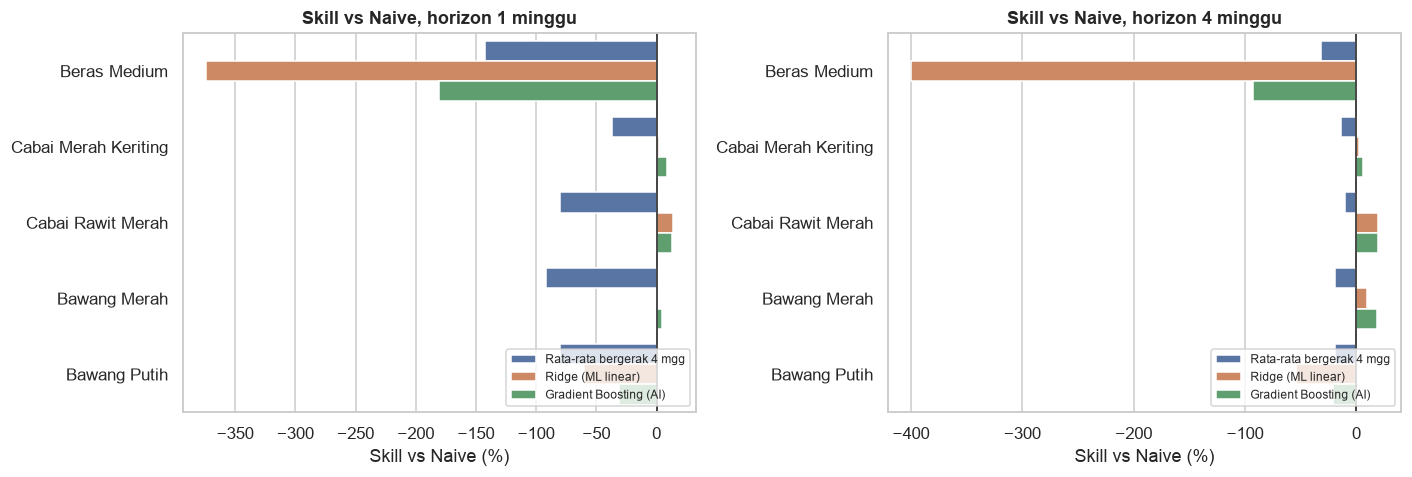

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sk = ev_kom[ev_kom.model.isin(["Gradient Boosting (AI)", "Ridge (ML linear)", "Rata-rata bergerak 4 mgg"])]
for ax, h in zip(axes, [1, 4]):
    sns.barplot(data=sk[sk.h == h], y="komoditas", x="Skill vs Naive (%)", hue="model", ax=ax, order=KOM)
    ax.axvline(0, color="k", lw=1); ax.set_title(f"Skill vs Naive, horizon {h} minggu"); ax.set_ylabel("")
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

### Kalibrasi interval prediksi 80 %

In [12]:
cov = []
for h in (1, 4):
    d = data[uji & data[f"y_{h}"].notna()]
    lo, hi = pred[h].loc[d.index, "q10"], pred[h].loc[d.index, "q90"]
    inside = (d[f"y_{h}"] >= lo) & (d[f"y_{h}"] <= hi)
    cov.append({"h": h, "cakupan interval 80% (%)": inside.mean()*100,
                "lebar rata-rata (% harga)": (np.exp(hi) - np.exp(lo)).mean()*100})
pd.DataFrame(cov).set_index("h")

,cakupan interval 80% (%),lebar rata-rata (% harga)
h,,
1,80.162,14.137
4,77.147,32.984


### Contoh: aktual vs prediksi 4 minggu ke depan

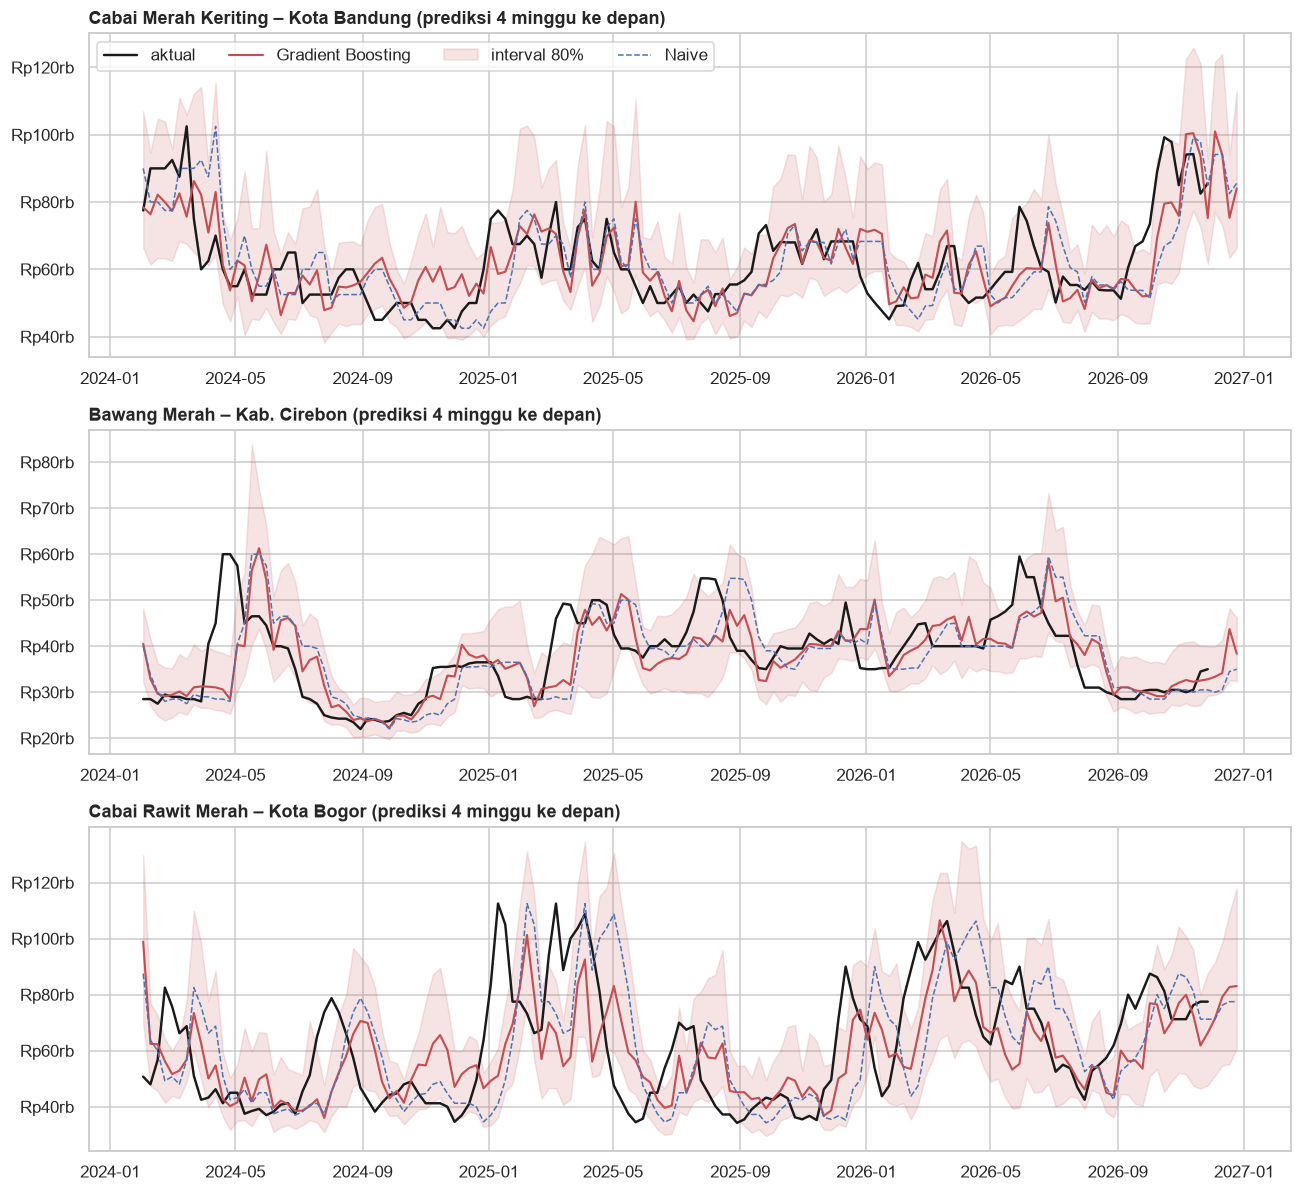

In [13]:
def plot_seri(kab, kom, h=4, ax=None):
    d = data[uji & (data.kabkota == kab) & (data.komoditas == kom)].copy()
    t = d.tanggal + pd.Timedelta(weeks=h)
    ax = ax or plt.gca()
    ax.plot(t, d[f"harga_{h}"], color="k", lw=1.6, label="aktual")
    ax.plot(t, d.harga_isi * np.exp(pred[h].loc[d.index, "Gradient Boosting (AI)"]), color="C3", lw=1.4, label="Gradient Boosting")
    ax.fill_between(t, d.harga_isi*np.exp(pred[h].loc[d.index, "q10"]), d.harga_isi*np.exp(pred[h].loc[d.index, "q90"]),
                    color="C3", alpha=.15, label="interval 80%")
    ax.plot(t, d.harga_isi, color="C0", lw=1, ls="--", label="Naive")
    ax.set_title(f"{kom} – {kab} (prediksi {h} minggu ke depan)", loc="left"); ax.yaxis.set_major_formatter(rupiah)

fig, axes = plt.subplots(3, 1, figsize=(12, 11))
for ax, (kab, kom) in zip(axes, [("Kota Bandung", "Cabai Merah Keriting"), ("Kab. Cirebon", "Bawang Merah"),
                                 ("Kota Bogor", "Cabai Rawit Merah")]):
    plot_seri(kab, kom, ax=ax)
axes[0].legend(ncol=4); plt.tight_layout(); plt.show()

## 7. Evaluasi peringatan dini (klasifikasi lonjakan)

**Lonjakan** = harga naik **> 10 % dalam 4 minggu ke depan**. Ini kejadian yang paling penting bagi TPID.

Pembanding non-AI (aturan sederhana yang bisa diterapkan tanpa AI):
- **Aturan momentum** — alarm jika harga sudah naik > 10 % dalam 4 minggu terakhir
- **Aturan musiman** — alarm jika pada periode yang sama tahun lalu terjadi lonjakan

Model AI: `HistGradientBoostingClassifier` (tanpa pembobotan kelas, agar probabilitas yang ditampilkan di dashboard tetap bermakna).

**Ambang alarm — prinsip "anggaran alarm yang sama":** TPID tidak bisa menindaklanjuti alarm setiap minggu.
Ambang dipilih pada periode validasi 2023 sehingga **frekuensi alarm AI = frekuensi lonjakan historis** di data latih
(± 20 % minggu), kira-kira sama dengan frekuensi alarm aturan non-AI. Dengan jumlah alarm yang setara,
perbandingannya adil: *siapa yang alarmnya lebih tepat sasaran?* (Memaksimalkan F1 saja cenderung memilih ambang
sangat rendah → alarm hampir setiap minggu, tidak berguna secara operasional.)

In [14]:
def clf():
    return HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=15, min_samples_leaf=40,
                                          l2_regularization=1.0, categorical_features=KATEGORI,
                                          random_state=SEED)
def fp_clf(tr, te):
    tr = tr.dropna(subset=["lonjakan"])
    return clf().fit(tr[FITUR], tr.lonjakan.astype(int)).predict_proba(te[FITUR])[:, 1]

prob_val = walk_forward(data, VAL_START, TEST_START, fp_clf, h=4)
yv = data.loc[prob_val.index, "lonjakan"]; ok = yv.notna()
laju_lonjakan = data[data.tanggal < VAL_START].lonjakan.mean()
AMBANG = round(float(prob_val.quantile(1 - laju_lonjakan)), 3)
a_val = prob_val[ok] >= AMBANG
print(f"Frekuensi lonjakan historis (data latih)  : {laju_lonjakan*100:.1f}% minggu")
print(f"Ambang alarm terpilih (validasi 2023)     : {AMBANG:.3f}")
print(f"Validasi 2023 -> alarm {a_val.mean()*100:.1f}% minggu | presisi {precision_score(yv[ok], a_val):.3f} | "
      f"recall {recall_score(yv[ok], a_val):.3f} | F1 {f1_score(yv[ok], a_val):.3f}")

prob = walk_forward(data, TEST_START, END, fp_clf, h=4)

Frekuensi lonjakan historis (data latih)  : 21.2% minggu
Ambang alarm terpilih (validasi 2023)     : 0.406
Validasi 2023 -> alarm 21.3% minggu | presisi 0.434 | recall 0.365 | F1 0.396


In [15]:
d = data.loc[prob.index].assign(prob=prob)
d = d[d.lonjakan.notna()]
lj = full.set_index(key).lonjakan
d["lonjakan_tahun_lalu"] = (d[key].assign(tanggal=d.tanggal - pd.Timedelta(weeks=52))
                              .merge(lj.reset_index(), on=key, how="left").lonjakan.fillna(0).values)
y = d.lonjakan.astype(int)
alarm = {"Aturan momentum (non-AI)": (np.exp(d.ret_4) - 1 > 0.10),
         "Aturan musiman (non-AI)": d.lonjakan_tahun_lalu == 1,
         "Gradient Boosting (AI)": d.prob >= AMBANG}
def skor(y, a, p=None):
    return {"Presisi": precision_score(y, a), "Recall": recall_score(y, a), "F1": f1_score(y, a),
            "PR-AUC": average_precision_score(y, p) if p is not None else np.nan,
            "ROC-AUC": roc_auc_score(y, p) if p is not None else np.nan, "% minggu alarm": a.mean()*100}
kl = pd.DataFrame({m: skor(y, a, d.prob if m.startswith("Gradient") else None) for m, a in alarm.items()}).T
print(f"Periode uji: {len(d):,} minggu-seri, {y.mean()*100:.1f}% di antaranya benar-benar lonjakan")
kl.style.format("{:.3f}").highlight_max(subset=["Presisi", "Recall", "F1"], color="#c7e9c0")

Periode uji: 6,660 minggu-seri, 19.8% di antaranya benar-benar lonjakan


,Presisi,Recall,F1,PR-AUC,ROC-AUC,% minggu alarm
Aturan momentum (non-AI),0.255,0.256,0.255,nan,nan,19.865
Aturan musiman (non-AI),0.270,0.291,0.280,nan,nan,21.336
Gradient Boosting (AI),0.503,0.418,0.457,0.499,0.809,16.441


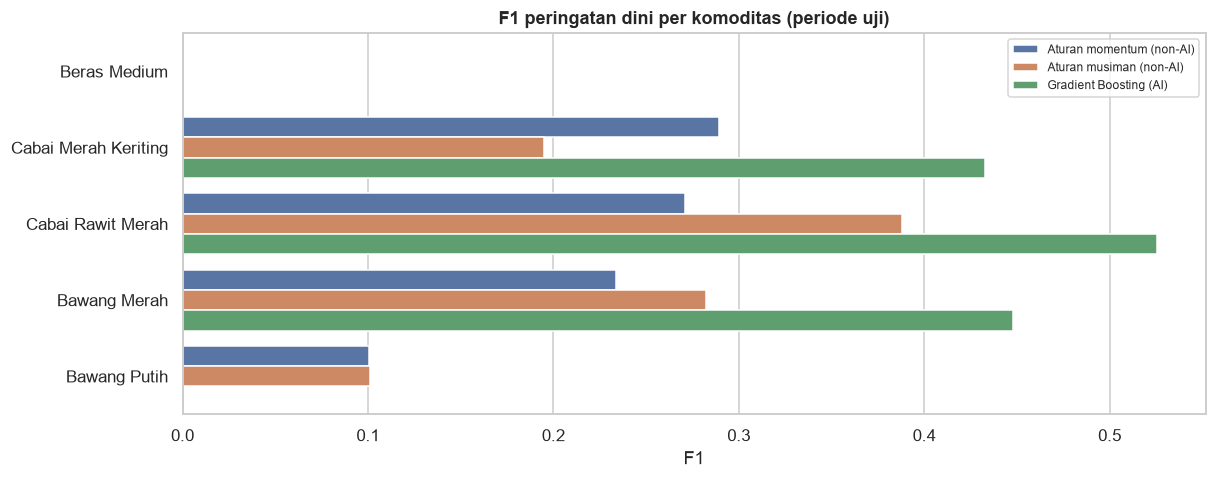

In [16]:
kl_kom = []
for k in KOM:
    s = d.komoditas == k
    for m, a in alarm.items():
        if y[s].sum() == 0: continue
        kl_kom.append({"komoditas": k, "model": m, "F1": f1_score(y[s], a[s]),
                       "Recall": recall_score(y[s], a[s]), "Presisi": precision_score(y[s], a[s], zero_division=0)})
kl_kom = pd.DataFrame(kl_kom)
ax = sns.barplot(data=kl_kom, y="komoditas", x="F1", hue="model", order=KOM)
ax.set_title("F1 peringatan dini per komoditas (periode uji)"); ax.set_ylabel(""); ax.legend(fontsize=8); plt.show()

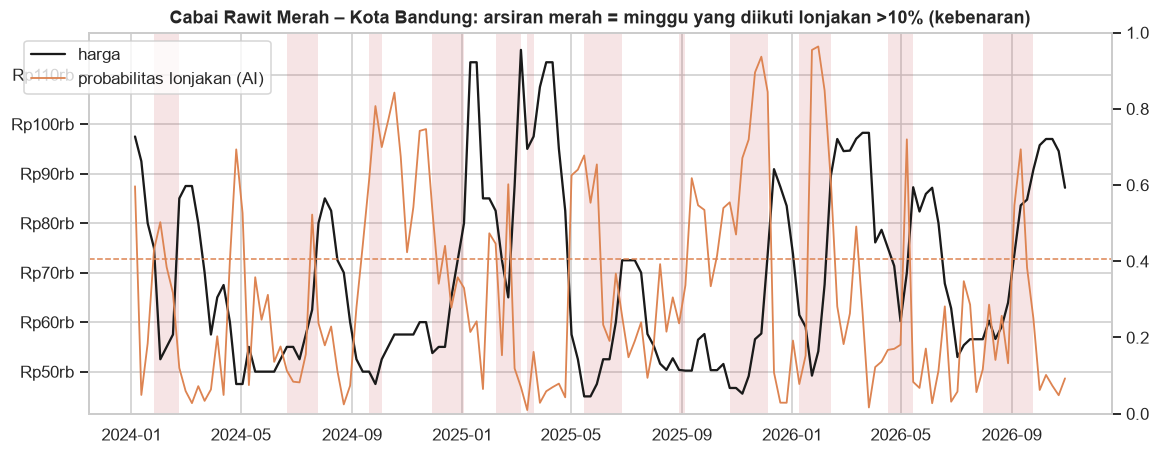

In [17]:
# Kapan alarm AI menyala dibanding lonjakan nyata — contoh Cabai Rawit Merah, Kota Bandung
s = d[(d.kabkota == "Kota Bandung") & (d.komoditas == "Cabai Rawit Merah")]
fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.plot(s.tanggal, s.harga_isi, color="k", lw=1.5, label="harga")
ax1.yaxis.set_major_formatter(rupiah)
for t in s.tanggal[s.lonjakan == 1]:
    ax1.axvspan(t, t + pd.Timedelta(days=7), color="C3", alpha=.15, lw=0)
ax2 = ax1.twinx(); ax2.plot(s.tanggal, s.prob, color="C1", lw=1.2, label="probabilitas lonjakan (AI)")
ax2.axhline(AMBANG, color="C1", ls="--", lw=1); ax2.set_ylim(0, 1); ax2.grid(False)
ax1.set_title("Cabai Rawit Merah – Kota Bandung: arsiran merah = minggu yang diikuti lonjakan >10% (kebenaran)")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.88)); plt.show()

## 8. Uji: apakah AI benar-benar diperlukan? (komponen e)

Kriteria keputusan yang ditetapkan **sebelum** melihat hasil uji:
1. AI dianggap **diperlukan** bila mengalahkan *seluruh* baseline non-AI pada periode uji secara bermakna
   (MAPE lebih rendah dan uji Diebold-Mariano signifikan, p < 0,05), **dan/atau** menghasilkan peringatan dini dengan F1 lebih tinggi.
2. Bila AI tidak lebih baik untuk komoditas tertentu, rekomendasinya adalah memakai metode non-AI yang lebih sederhana
   untuk komoditas tersebut.

In [18]:
from scipy import stats
def diebold_mariano(e1, e2, h):
    """H0: akurasi sama. Statistik DM dengan koreksi Harvey dkk. (loss = |error|)."""
    dlt = np.abs(e1) - np.abs(e2); n = len(dlt); dm = dlt.mean()
    gamma = [np.cov(dlt[k:], dlt[:n-k])[0, 1] if k else dlt.var() for k in range(h)]
    v = (gamma[0] + 2*sum(gamma[1:])) / n
    stat = dm / np.sqrt(v) * np.sqrt((n + 1 - 2*h + h*(h-1)/n) / n)
    return stat, 2 * stats.t.sf(abs(stat), df=n-1)

rows = []
for h in H:
    dd = data[uji & data[f"y_{h}"].notna()]
    # rata-rata galat per tanggal (agregat 45 seri) agar uji tidak terlalu optimistis akibat korelasi antar seri
    err = lambda m: (dd.harga_isi*np.exp(pred[h].loc[dd.index, m]) / dd[f"harga_{h}"] - 1).groupby(dd.tanggal).apply(lambda e: e.abs().mean())
    eA = err("Gradient Boosting (AI)")
    for b in BASE:
        eB = err(b); idx = eA.index.intersection(eB.dropna().index)
        st, p = diebold_mariano(eB[idx].values, eA[idx].values, h)
        rows.append({"h": h, "pembanding": b, "MAPE baseline": eB[idx].mean()*100, "MAPE AI": eA[idx].mean()*100,
                     "DM stat": st, "p-value": p, "AI lebih baik & signifikan": (st > 0) and (p < 0.05)})
dm = pd.DataFrame(rows); dm.style.format({"MAPE baseline": "{:.2f}", "MAPE AI": "{:.2f}", "DM stat": "{:.2f}", "p-value": "{:.4f}"})

,h,pembanding,MAPE baseline,MAPE AI,DM stat,p-value,AI lebih baik & signifikan
0,1,Naive,5.18,4.86,2.51,0.0133,True
1,1,Perubahan tahun lalu,8.33,4.86,12.70,0.0000,True
2,1,Rata-rata bergerak 4 mgg,8.68,4.86,10.89,0.0000,True
3,1,Tren linear 8 mgg,6.12,4.86,8.68,0.0000,True
4,2,Naive,8.53,7.89,2.37,0.0190,True
5,2,Perubahan tahun lalu,13.22,7.89,7.61,0.0000,True
6,2,Rata-rata bergerak 4 mgg,11.16,7.89,5.38,0.0000,True
7,2,Tren linear 8 mgg,10.73,7.89,6.67,0.0000,True
8,3,Naive,10.85,9.75,2.42,0.0167,True
9,3,Perubahan tahun lalu,16.91,9.75,5.88,0.0000,True


In [19]:
# Rekap keputusan per komoditas (horizon 4 minggu & peringatan dini)
rek = []
for k in KOM:
    e = ev_kom[(ev_kom.komoditas == k) & (ev_kom.h == 4)].set_index("model")["MAPE (%)"]
    best_base = e[BASE].idxmin()
    f = kl_kom[kl_kom.komoditas == k].set_index("model").F1
    rek.append({"komoditas": k, "MAPE AI": e["Gradient Boosting (AI)"], "baseline terbaik": best_base,
                "MAPE baseline terbaik": e[best_base],
                "perbaikan MAPE (%)": (1 - e["Gradient Boosting (AI)"]/e[best_base])*100,
                "F1 AI": f.get("Gradient Boosting (AI)", np.nan),
                "F1 non-AI terbaik": f.drop("Gradient Boosting (AI)", errors="ignore").max()})
rek = pd.DataFrame(rek).set_index("komoditas")
rek["AI diperlukan?"] = np.where((rek["perbaikan MAPE (%)"] > 2) | (rek["F1 AI"] > rek["F1 non-AI terbaik"] + 0.05),
                                 "Ya", "Tidak / cukup non-AI")
rek.style.format({c: "{:.2f}" for c in rek.columns if pd.api.types.is_float_dtype(rek[c])})

,MAPE AI,baseline terbaik,MAPE baseline terbaik,perbaikan MAPE (%),F1 AI,F1 non-AI terbaik,AI diperlukan?
komoditas,,,,,,,
Beras Medium,1.42,Naive,0.74,-92.77,0.00,0.00,Tidak / cukup non-AI
Cabai Merah Keriting,16.84,Naive,17.85,5.64,0.43,0.29,Ya
Cabai Rawit Merah,22.44,Naive,27.84,19.40,0.53,0.39,Ya
Bawang Merah,12.02,Naive,14.77,18.60,0.45,0.28,Ya
Bawang Putih,4.36,Naive,3.60,-21.10,0.00,0.10,Tidak / cukup non-AI


## 9. Interpretasi model: faktor pendorong lonjakan

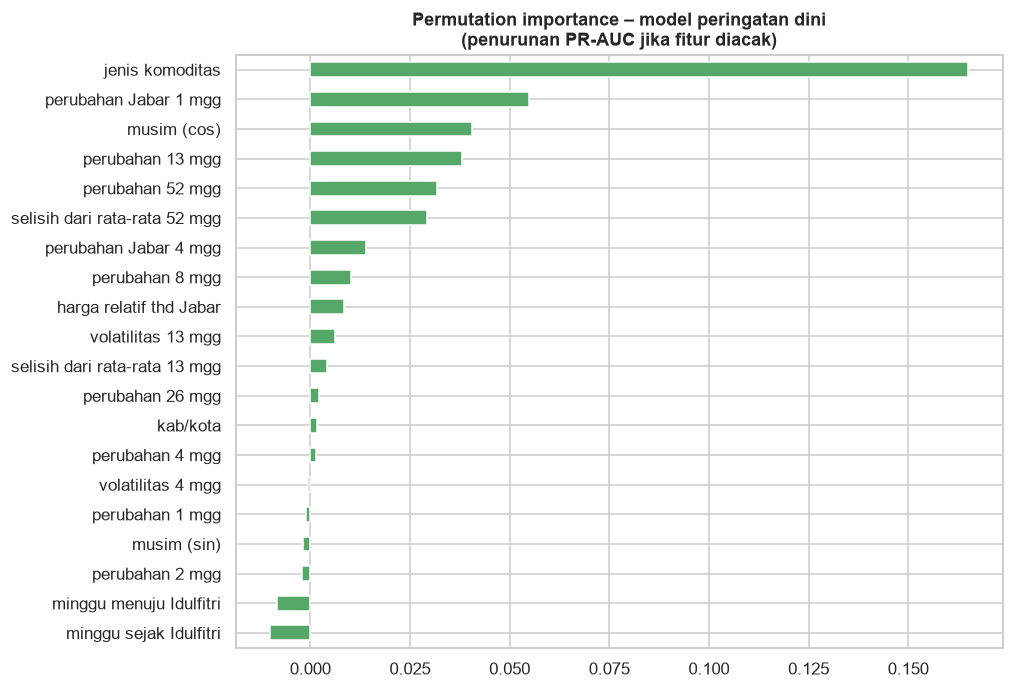

In [20]:
tr = data[data.tanggal < TEST_START].dropna(subset=["lonjakan"])
te = data[uji].dropna(subset=["lonjakan"])
m_clf = clf().fit(tr[FITUR], tr.lonjakan.astype(int))
pi = permutation_importance(m_clf, te[FITUR], te.lonjakan.astype(int), scoring="average_precision",
                            n_repeats=5, random_state=SEED, n_jobs=-1)
LABEL = {"ret_1": "perubahan 1 mgg", "ret_2": "perubahan 2 mgg", "ret_4": "perubahan 4 mgg", "ret_8": "perubahan 8 mgg",
         "ret_13": "perubahan 13 mgg", "ret_26": "perubahan 26 mgg", "ret_52": "perubahan 52 mgg",
         "vol_4": "volatilitas 4 mgg", "vol_13": "volatilitas 13 mgg", "dev_ma13": "selisih dari rata-rata 13 mgg",
         "dev_ma52": "selisih dari rata-rata 52 mgg", "jabar_ret_1": "perubahan Jabar 1 mgg",
         "jabar_ret_4": "perubahan Jabar 4 mgg", "rel_jabar": "harga relatif thd Jabar",
         "woy_sin": "musim (sin)", "woy_cos": "musim (cos)", "ke_lebaran": "minggu menuju Idulfitri",
         "sejak_lebaran": "minggu sejak Idulfitri", "kom": "jenis komoditas", "kab": "kab/kota"}
imp = (pd.Series(pi.importances_mean, index=FITUR).rename(LABEL).sort_values())
ax = imp.plot.barh(figsize=(9, 7), color="C2")
ax.set_title("Permutation importance – model peringatan dini\n(penurunan PR-AUC jika fitur diacak)"); plt.show()

## 10. Model final, prediksi terbaru & ekspor data dashboard

In [21]:
akhir = data.tanggal.max()
kini = buat_fitur(wk); kini = kini[kini.tanggal == akhir].dropna(subset=FITUR)
fc = []
for h in H:
    tr = data.dropna(subset=[f"y_{h}"])
    m50 = gbm(**BEST).fit(tr[FITUR], tr[f"y_{h}"])
    m10 = gbm(quantile=.1, **BEST).fit(tr[FITUR], tr[f"y_{h}"])
    m90 = gbm(quantile=.9, **BEST).fit(tr[FITUR], tr[f"y_{h}"])
    fc.append(kini[["kabkota", "komoditas", "harga_isi"]].assign(
        h=h, tanggal=akhir + pd.Timedelta(weeks=h),
        p50=kini.harga_isi*np.exp(m50.predict(kini[FITUR])),
        p10=kini.harga_isi*np.exp(m10.predict(kini[FITUR])),
        p90=kini.harga_isi*np.exp(m90.predict(kini[FITUR])) ))
fc = pd.concat(fc)
# Komoditas non-AI (hibrida): prediksi Naive + interval empiris (kuantil perubahan h-minggu, 2 tahun terakhir)
def interval_empiris(h, sebelum):
    d2 = data[(data.tanggal <= sebelum - pd.Timedelta(weeks=h)) & (data.tanggal > sebelum - pd.Timedelta(weeks=104 + h))]
    return d2.groupby("komoditas")[f"y_{h}"].quantile([.1, .9]).unstack()
for h in H:
    q = interval_empiris(h, akhir)
    m = (fc.h == h) & ~fc.komoditas.isin(PAKAI_AI)
    fc.loc[m, "p50"] = fc.loc[m, "harga_isi"]
    fc.loc[m, "p10"] = fc.loc[m, "harga_isi"] * np.exp(fc.loc[m, "komoditas"].map(q[0.1]))
    fc.loc[m, "p90"] = fc.loc[m, "harga_isi"] * np.exp(fc.loc[m, "komoditas"].map(q[0.9]))
fc["model"] = np.where(fc.komoditas.isin(PAKAI_AI), "Gradient Boosting (AI)", "Naive")
tr = data.dropna(subset=["lonjakan"])
m_final = clf().fit(tr[FITUR], tr.lonjakan.astype(int))
status = kini[["kabkota", "komoditas", "harga_isi"]].assign(prob=m_final.predict_proba(kini[FITUR])[:, 1])
status["status"] = np.select([status.prob >= AMBANG, status.prob >= AMBANG/2], ["merah", "kuning"], "hijau")
status = status.merge(fc[fc.h == 4][["kabkota", "komoditas", "p50"]], on=["kabkota", "komoditas"])
status["perubahan_4mgg"] = (status.p50/status.harga_isi - 1)*100
print(f"Data terakhir: {akhir:%d %b %Y}")
status.pivot(index="kabkota", columns="komoditas", values="status")[KOM]

Data terakhir: 27 Nov 2026


komoditas,Beras Medium,Cabai Merah Keriting,Cabai Rawit Merah,Bawang Merah,Bawang Putih
kabkota,,,,,
Kab. Cirebon,hijau,hijau,merah,merah,hijau
Kab. Tasikmalaya,hijau,hijau,merah,merah,hijau
Kota Bandung,hijau,hijau,merah,merah,hijau
Kota Bekasi,hijau,hijau,merah,merah,hijau
Kota Bogor,hijau,hijau,merah,merah,hijau
Kota Cirebon,hijau,kuning,merah,merah,hijau
Kota Depok,hijau,kuning,merah,merah,hijau
Kota Sukabumi,hijau,hijau,merah,merah,hijau
Kota Tasikmalaya,hijau,hijau,merah,kuning,hijau


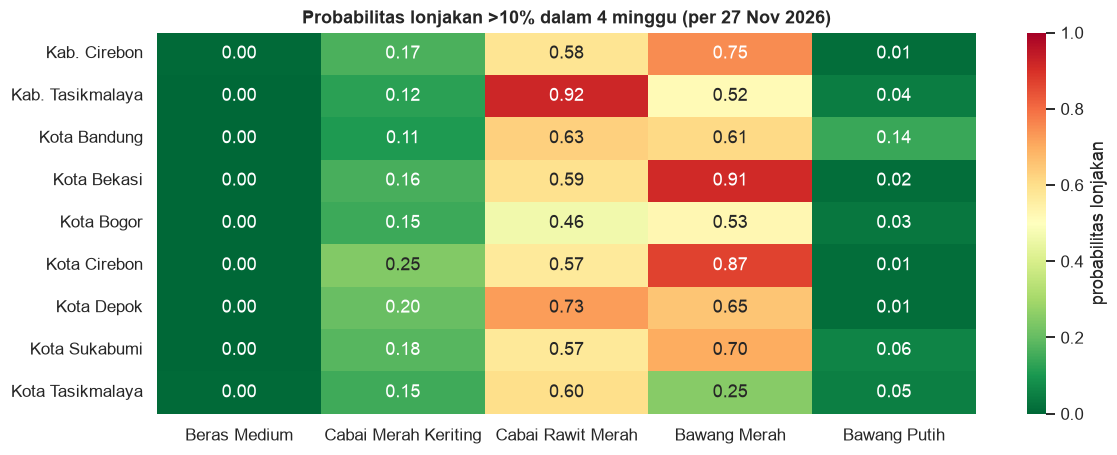

In [22]:
pv = status.pivot(index="kabkota", columns="komoditas", values="prob")[KOM]
ax = sns.heatmap(pv, annot=True, fmt=".2f", cmap="RdYlGn_r", vmin=0, vmax=1, cbar_kws={"label": "probabilitas lonjakan"})
ax.set_title(f"Probabilitas lonjakan >10% dalam 4 minggu (per {akhir:%d %b %Y})"); ax.set_xlabel(""); ax.set_ylabel(""); plt.show()

In [23]:
# ===== Ekspor ke docs/data/dashboard.json (dibaca dashboard GitHub Pages) =====
r0 = lambda x: None if pd.isna(x) else int(round(float(x)))
r3 = lambda x: None if pd.isna(x) else round(float(x), 3)
hist = {k: {kb: [[t.strftime("%Y-%m-%d"), r0(v)] for t, v in zip(g.tanggal, g.harga_isi)]
            for kb, g in wk[wk.komoditas == k].groupby("kabkota")} for k in KOM}
fcj = {k: {kb: [{"h": int(r.h), "tanggal": r.tanggal.strftime("%Y-%m-%d"), "p10": r0(r.p10), "p50": r0(r.p50), "p90": r0(r.p90)}
                for r in g.itertuples()] for kb, g in fc[fc.komoditas == k].groupby("kabkota")} for k in KOM}
stj = {k: {r.kabkota: {"prob": r3(r.prob), "status": r.status, "harga": r0(r.harga_isi),
                       "pred_4mgg": r0(r.p50), "perubahan_4mgg": round(float(r.perubahan_4mgg), 1)}
           for r in status[status.komoditas == k].itertuples()} for k in KOM}
qe = interval_empiris(4, TEST_START)   # interval empiris untuk komoditas Naive, hanya dari data sebelum periode uji
bt = data[uji & data.y_4.notna()].copy()
ai_ = bt.komoditas.isin(PAKAI_AI)
bt["ai"] = bt.harga_isi*np.exp(pred[4].loc[bt.index, "Hibrida (AI + Naive)"])
bt["lo"] = np.where(ai_, bt.harga_isi*np.exp(pred[4].loc[bt.index, "q10"]), bt.harga_isi*np.exp(bt.komoditas.map(qe[0.1])))
bt["hi"] = np.where(ai_, bt.harga_isi*np.exp(pred[4].loc[bt.index, "q90"]), bt.harga_isi*np.exp(bt.komoditas.map(qe[0.9])))
btj = {k: {kb: [[(t + pd.Timedelta(weeks=4)).strftime("%Y-%m-%d"), r0(a), r0(n), r0(p), r0(l), r0(u)]
                for t, a, n, p, l, u in zip(g.tanggal, g.harga_4, g.harga_isi, g.ai, g.lo, g.hi)]
           for kb, g in bt[bt.komoditas == k].groupby("kabkota")} for k in KOM}
out = {
    "meta": {"dibuat": pd.Timestamp.now().strftime("%Y-%m-%d"), "dibuat_utc": pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%dT%H:%M:%SZ"), "data_terakhir": akhir.strftime("%Y-%m-%d"),
             "komoditas": KOM, "kabkota": KAB, "ambang_alarm": AMBANG,
             "model_per_komoditas": {k: ("Gradient Boosting (AI)" if k in PAKAI_AI else "Naive") for k in KOM},
             "catatan_tanggal": "data mingguan berlabel Jumat akhir minggu; minggu terakhir bisa parsial", "periode_uji": [TEST_START.strftime("%Y-%m-%d"), akhir.strftime("%Y-%m-%d")],
             "sumber": "PIHPS Bank Indonesia (pasar tradisional), diolah"},
    "histori": hist, "prediksi": fcj, "status": stj,
    "backtest_kolom": ["tanggal_target", "aktual", "naive", "sistem", "p10", "p90"], "backtest": btj,
    "metrik_regresi": ev.round(3).to_dict(orient="records"),
    "metrik_regresi_komoditas": ev_kom.round(3).to_dict(orient="records"),
    "metrik_klasifikasi": kl.reset_index(names="model").round(3).to_dict(orient="records"),
    "metrik_klasifikasi_komoditas": kl_kom.round(3).to_dict(orient="records"),
    "uji_dm": dm.round(4).astype({"AI lebih baik & signifikan": bool}).to_dict(orient="records"),
    "rekap_kebutuhan_ai": rek.reset_index().round(3).to_dict(orient="records"),
    "kepentingan_fitur": [{"fitur": k, "nilai": r3(v)} for k, v in imp.sort_values(ascending=False).items()],
}
dst = Path("..") / "docs/data"; dst.mkdir(parents=True, exist_ok=True)
def bersih(o):   # NaN/inf -> null agar JSON valid untuk JavaScript
    if isinstance(o, dict): return {k: bersih(v) for k, v in o.items()}
    if isinstance(o, list): return [bersih(v) for v in o]
    if isinstance(o, (float, np.floating)): return None if not np.isfinite(o) else float(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, np.bool_): return bool(o)
    return o
with open(dst / "dashboard.json", "w") as f:
    json.dump(bersih(out), f, ensure_ascii=False, separators=(",", ":"), allow_nan=False)
print(f"Tersimpan {dst/'dashboard.json'} ({(dst/'dashboard.json').stat().st_size/1024:,.0f} KB)")

Tersimpan ../docs/data/dashboard.json (713 KB)


## 11. Kesimpulan analisis

**Desain evaluasi.** Data mingguan Jan 2020 – Nov 2026 (45 seri). Pemilihan hyperparameter, model per komoditas,
dan ambang alarm dilakukan pada **validasi 2023**; hasil dilaporkan pada **periode uji Jan 2024 – Nov 2026**
dengan *walk-forward* (latih ulang tiap 8 minggu, tanpa informasi masa depan).

**1. Prediksi harga — AI lebih akurat dari semua pembanding non-AI secara agregat.**
MAPE Gradient Boosting 4,86 % (h = 1 minggu) dan 11,42 % (h = 4 minggu), dibanding Naive 5,18 % dan 12,96 %.
Uji Diebold-Mariano menunjukkan keunggulan AI **signifikan (p < 0,05) terhadap keempat baseline pada semua horizon**.
Model linear (Ridge) hanya sedikit lebih baik dari Naive → pola harga bersifat **non-linear**, sehingga model berbasis
pohon diperlukan.

**2. Tetapi AI tidak diperlukan untuk semua komoditas (jawaban komponen e).**
| Komoditas | MAPE AI (h=4) | MAPE Naive (h=4) | Kesimpulan |
|---|---|---|---|
| Cabai Rawit Merah | 22,4 % | 27,8 % | AI jauh lebih baik (−19 %) |
| Bawang Merah | 12,0 % | 14,8 % | AI jauh lebih baik (−19 %) |
| Cabai Merah Keriting | 16,8 % | 17,9 % | AI sedikit lebih baik (−6 %) |
| Bawang Putih | 4,4 % | 3,6 % | **Naive lebih baik** |
| Beras Medium | 1,4 % | 0,7 % | **Naive lebih baik** — harga dikendalikan HET/SPHP |

Karena itu sistem dirancang **hibrida**: model per komoditas dipilih pada validasi 2023 → AI untuk cabai rawit &
bawang merah, Naive untuk beras, bawang putih, dan cabai merah keriting (pada validasi 2023 AI belum unggul untuk
cabai merah keriting; pada periode uji ternyata AI sedikit lebih baik — dicatat sebagai bahan evaluasi ulang).
MAPE sistem hibrida h = 4: **11,33 %** (terbaik dari semua pendekatan).

**3. Peringatan dini — AI hampir dua kali lebih tepat sasaran.**
Pada "anggaran alarm" yang setara (± 16–21 % minggu), **presisi alarm AI 0,50** vs 0,26 (aturan momentum) dan
0,27 (aturan musiman); **F1 0,46 vs 0,26–0,28**. Artinya, setengah dari alarm AI benar-benar diikuti lonjakan > 10 %,
sementara aturan sederhana hanya seperempatnya. ROC-AUC 0,81 menunjukkan kemampuan membedakan yang baik.
Keunggulan terbesar pada cabai rawit merah (F1 0,53 vs 0,39), bawang merah (0,45 vs 0,28), dan cabai merah keriting
(0,43 vs 0,29). Untuk beras dan bawang putih lonjakan sangat jarang sehingga tidak ada metode yang mampu
memprediksinya — konsisten dengan kesimpulan butir 2.

**4. Interval prediksi terkalibrasi.** Cakupan interval 80 %: 80,2 % (h = 1) dan 77,1 % (h = 4) → ketidakpastian
yang ditampilkan di dashboard dapat dipercaya.

**5. Faktor pendorong lonjakan** (*permutation importance*): jenis komoditas, perubahan harga rata-rata Jawa Barat
minggu lalu (guncangan regional menjalar), posisi musim, serta perubahan harga 13 & 52 minggu
(siklus jangka menengah dan tahunan).

**Keterbatasan.** (a) Hanya 9 kab/kota perkotaan yang dipantau PIHPS; (b) belum memakai variabel pasokan/cuaca
(curah hujan, produksi, stok) yang bisa meningkatkan akurasi; (c) interpolasi celah data ≤ 3 minggu di notebook 01
memakai nilai sesudahnya (pengaruh kecil karena data hilang hanya 3,4 %); (d) presisi 0,50 berarti separuh alarm
masih "alarm palsu" — alarm sebaiknya dipakai sebagai pemicu pemantauan intensif, bukan langsung operasi pasar.

**Hasil untuk dashboard:** `docs/data/dashboard.json` — histori harga, prediksi 1–4 minggu + interval 80 %,
status peringatan per kab/kota × komoditas, hasil *backtest*, dan seluruh metrik evaluasi.